---
title: "L5-09 · Entropy and quantum tomography"
short_title: "Entropy and quantum tomography"
subtitle: "Mixedness is the Shannon entropy of a density operator's eigenvalues, and the density operator itself can only be estimated, never read off, by measuring many identical copies in enough different bases."
description: "Compute the von Neumann entropy of a qubit from its Bloch vector, and reconstruct a qubit state from Pauli measurement counts with an error estimate and a physical correction."
tags: [level-5, coursebook]
---

(lesson-l5-09)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 100 minutes  
**Big idea.** Mixedness is the Shannon entropy of a density operator's eigenvalues, and the density operator itself can only be estimated, never read off, by measuring many identical copies in enough different bases.  
**Before this lesson.** [L5-05](#lesson-l5-05), [L3-08](#lesson-l3-08)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Compute $S(\rho)$ in bits from the eigenvalues of $\rho$, and for a qubit from the Bloch length through $S = h\big((1 + |\vec r|)/2\big)$.
- Reconstruct a qubit density matrix from $X$, $Y$, $Z$ counts by linear inversion and give each component's standard error $\sqrt{(1 - r_i^2)/N}$.
- Recognize an unphysical estimate ($|\hat r| > 1$, a negative eigenvalue) and replace it by the closest physical state in Hilbert-Schmidt distance.
- Explain why full tomography of $n$ qubits needs $4^n - 1$ real parameters and $3^n$ local Pauli settings.

## Why this matters

A collaborator hands you a box that is said to emit qubits in the state $|0\rangle$. How would you check? One copy measured once gives one bit, and the no-cloning property of quantum states means you cannot copy the qubit to look again. A single measurement basis is not enough either: the mixture $\tfrac12 I$ and the state $|{+}\rangle$ both give a fair coin in the $Z$ basis, and only a measurement in another basis tells them apart. Checking a quantum state is a statistics problem with a quantum twist.

Two quantities organize the problem. The von Neumann entropy says how mixed the state is: 0 bits for a pure state, 1 bit for a maximally mixed qubit. Tomography says how to estimate the whole density matrix from counts, how large the error is for a given number of shots, and what to do when the noisy estimate is not a valid state at all. Both ideas reappear whenever a quantum experiment claims to have prepared something, and both set the cost of checking larger systems, which grows exponentially with the number of qubits.

:::{dropdown} Key terms

**von Neumann entropy**
: $S(\rho) = -\operatorname{Tr}(\rho\log_2\rho) = -\sum_j \lambda_j\log_2\lambda_j$, the Shannon entropy of the eigenvalues of $\rho$, in bits.

**Bloch vector**
: The vector $\vec r = (r_x, r_y, r_z)$ with $\rho = \tfrac12(I + r_x X + r_y Y + r_z Z)$; physical states have $|\vec r| \le 1$.

**Quantum state tomography**
: Estimating an unknown $\rho$ from the outcome counts of measurements on many identically prepared copies.

**Linear inversion**
: The estimator $\hat r_i = (n_i^{+} - n_i^{-})/N$ that replaces each expectation value by its sample mean and solves for $\rho$.

**Shot noise**
: Statistical fluctuation of an estimate caused by a finite number $N$ of single-shot outcomes; its size falls like $1/\sqrt N$.

**Physicality**
: The requirement that an estimate be a density operator: Hermitian, trace one, no negative eigenvalues.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_09 as _lessonfigs

## Entropy of a density operator

A density operator $\rho$ from [L5-05](#lesson-l5-05) is Hermitian, positive semidefinite and of trace one, so it has a spectral decomposition $\rho = \sum_j \lambda_j |e_j\rangle\langle e_j|$ with eigenvalues $\lambda_j \ge 0$ that sum to 1. The eigenvalues form a probability distribution, and the natural measure of how spread out it is was met in [L3-08](#lesson-l3-08): the Shannon entropy.

:::{prf:definition} von Neumann entropy
:label: def-l5-09-vn
The **von Neumann entropy** of a density operator $\rho$ with eigenvalues $\lambda_1, \dots, \lambda_d$ is $S(\rho) = -\operatorname{Tr}(\rho\log_2\rho) = -\sum_j \lambda_j\log_2\lambda_j$, with the convention $0\log_2 0 = 0$. Throughout this lesson logarithms are base 2 and entropy is in **bits**; with the natural logarithm the unit is the nat, and $S_{\text{nats}} = (\ln 2)\,S_{\text{bits}}$ [@nielsenchuang; @watrous].
:::

$$
S(\rho) = -\sum_j \lambda_j \log_2 \lambda_j
$$ (eq-l5-09-vn)

:::{prf:proposition} Entropy of a qubit depends only on the Bloch length
:label: prop-l5-09-qubit
If $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ with $\vec\sigma = (X, Y, Z)$, the eigenvalues of $\rho$ are $\lambda_\pm = (1 \pm |\vec r|)/2$, and $S(\rho) = h\big((1 + |\vec r|)/2\big)$ where $h(q) = -q\log_2 q - (1 - q)\log_2(1 - q)$ is the binary entropy.
:::

:::{prf:proof}
The Pauli matrices anticommute and square to $I$, so $(\vec r\cdot\vec\sigma)^2 = \sum_{i} r_i^2 I + \sum_{i \ne j} r_i r_j \sigma_i\sigma_j = |\vec r|^2 I$, because the cross terms cancel in pairs. Hence the eigenvalues of the traceless Hermitian matrix $\vec r\cdot\vec\sigma$ are $\pm|\vec r|$, and those of $\rho$ are $(1 \pm |\vec r|)/2$. Substituting them into [](#eq-l5-09-vn) gives $h\big((1 + |\vec r|)/2\big)$.
:::

$$
S(\rho) = h\!\left(\tfrac{1 + |\vec r|}{2}\right), \qquad \lambda_\pm = \tfrac{1 \pm |\vec r|}{2}
$$ (eq-l5-09-qubit)

:::{figure} ../../_static/animations/l5_09_entropy_radius.mp4
:alt: A state point slides from the edge of a Bloch disk to its center while two eigenvalue bars even out and a curve of entropy against Bloch length is traced; then the point circles at fixed length and the entropy stays 0.722.
:width: 100%

Entropy is a function of the distance from the center only: 0 bits on the pure surface, 1 bit at the maximally mixed center, and the same value all the way around a circle.
:::

:::{dropdown} What the animation shows
On the left is a slice through the Bloch ball. A violet state point starts on the boundary, where $|\vec r| = 1$, and slides along a radius to the center. Two bars in the middle show the eigenvalues $(1 \pm |\vec r|)/2$: at the start they are 1 and 0, at the center both are $1/2$. On the right a graph traces the entropy against the Bloch length as the point moves; it rises from 0 bits on the surface (pure: 0 bits) to 1 bit at the center (center: 1 bit) along $h\big((1 + |\vec r|)/2\big)$, steep near the surface and flat near the center. The point then stops at $|\vec r| = 0.6$, where the eigenvalues are 0.8 and 0.2 and $S = 0.722$ bits, and travels once around the circle of radius 0.6. The bars and the entropy do not change, because a unitary rotation moves the Bloch vector without changing its length.
:::

:::{prf:theorem} Range and invariance of the entropy
:label: thm-l5-09-bounds
For a density operator on a $d$-dimensional space, $0 \le S(\rho) \le \log_2 d$. The lower bound is attained exactly by pure states and the upper bound exactly by $\rho = I/d$. For every unitary $U$, $S(U\rho U^\dagger) = S(\rho)$.
:::

:::{prf:proof}
Each term $-\lambda\log_2\lambda$ is non-negative for $\lambda \in [0, 1]$ and vanishes only at $\lambda \in \{0, 1\}$, so $S = 0$ exactly when one eigenvalue is 1 and the rest are 0, that is, when $\rho = |e\rangle\langle e|$ is pure. For the upper bound write $\log_2 d - S(\rho) = \sum_j \lambda_j\log_2(d\lambda_j) = D(\lambda\,\|\,u)$, the relative entropy between the eigenvalue distribution and the uniform distribution $u_j = 1/d$. Gibbs' inequality gives $D \ge 0$ with equality only when $\lambda = u$, that is, $\rho = I/d$ [@coverthomas]. Finally $U\rho U^\dagger$ has the same eigenvalues as $\rho$, so the same entropy.
:::

:::{prf:example} A partly mixed qubit
:label: ex-l5-09-mixed
Measured means $r_x = 0$, $r_y = 0$, $r_z = 0.6$ give $|\vec r| = 0.6$, eigenvalues $(1 + 0.6)/2 = 0.8$ and $0.2$, and $S = -0.8\log_2 0.8 - 0.2\log_2 0.2 \approx 0.258 + 0.464 = 0.722$ bits. A pure qubit has 0 bits and $I/2$ has 1 bit, so in entropy this state is closer to maximally mixed than to pure, although its Bloch vector is 60 percent of the way out to the surface.
:::

## One basis cannot see the entropy

Measuring $\rho$ in an orthonormal basis $\{|k\rangle\}$ gives outcome $k$ with probability $p_k = \langle k|\rho|k\rangle$, the diagonal of $\rho$ in that basis. It is tempting to use the Shannon entropy $H(p)$ of those outcomes as the entropy of the state. It is never smaller, and it can be much larger.

:::{prf:proposition} Measurement entropy bounds the state entropy from above
:label: prop-l5-09-measure
For every orthonormal basis $\{|k\rangle\}$ the outcome distribution $p_k = \langle k|\rho|k\rangle$ satisfies $H(p) \ge S(\rho)$, with equality when the basis is an eigenbasis of $\rho$.
:::

:::{prf:proof}
Write $\rho = \sum_j \lambda_j|e_j\rangle\langle e_j|$. Then $p_k = \sum_j B_{kj}\lambda_j$ with $B_{kj} = |\langle k|e_j\rangle|^2$. Each row and each column of $B$ sums to 1, because both bases are orthonormal, so $B$ is doubly stochastic. The function $\eta(x) = -x\log_2 x$ is concave, and $p_k$ is a weighted average of the $\lambda_j$ with weights $B_{kj}$ that sum to 1 over $j$, so $\eta(p_k) \ge \sum_j B_{kj}\eta(\lambda_j)$ by Jensen's inequality. Summing over $k$ and using $\sum_k B_{kj} = 1$ gives $H(p) = \sum_k\eta(p_k) \ge \sum_j\eta(\lambda_j) = S(\rho)$. In an eigenbasis $B$ is a permutation matrix and equality holds.
:::

:::{warning} A fair coin from a pure state
The pure state $|{+}\rangle = (|0\rangle + |1\rangle)/\sqrt2$ has $S = 0$, yet its $Z$ outcomes are a fair coin with $H = 1$ bit. For a qubit, $H(Z\text{ outcomes}) = h\big((1 + r_z)/2\big) \ge h\big((1 + |\vec r|)/2\big)$ because $|r_z| \le |\vec r|$ and $h$ decreases on $[\tfrac12, 1]$. Counts in one basis cannot tell randomness that is in the state from randomness created by the choice of basis. That is why tomography uses several bases.
:::

## Tomography from Pauli expectation values

The $2\times 2$ Hermitian matrices form a real vector space of dimension 4, and $I, X, Y, Z$ are an orthogonal basis for the Hilbert-Schmidt inner product $\langle A, B\rangle = \operatorname{Tr}(A^\dagger B)$: $\operatorname{Tr}(\sigma_i\sigma_j) = 2\delta_{ij}$ and $\operatorname{Tr}\sigma_i = 0$. Expanding $\rho$ in this basis is all that qubit tomography needs.

:::{prf:theorem} Pauli reconstruction of a qubit
:label: thm-l5-09-recon
Every qubit density operator satisfies $\rho = \tfrac12\big(I + r_x X + r_y Y + r_z Z\big)$ with $r_i = \operatorname{Tr}(\rho\,\sigma_i) = \langle\sigma_i\rangle$, the expectation value of the $\pm 1$ outcome of measuring $\sigma_i$. Physical states are exactly those with $|\vec r| \le 1$.
:::

:::{prf:proof}
Write $\rho = \tfrac12(c_0 I + \sum_i c_i\sigma_i)$ with real $c$'s, possible because $\rho$ is Hermitian. Taking the trace gives $c_0 = \operatorname{Tr}\rho = 1$. Multiplying by $\sigma_j$ and taking the trace gives $\operatorname{Tr}(\rho\sigma_j) = \tfrac12 c_j\operatorname{Tr}(\sigma_j^2) = c_j$. The eigenvalues $(1 \pm |\vec r|)/2$ from [](#prop-l5-09-qubit) are non-negative exactly when $|\vec r| \le 1$.
:::

$$
\rho = \tfrac12\left(I + r_x X + r_y Y + r_z Z\right), \qquad r_i = \operatorname{Tr}(\rho\,\sigma_i)
$$ (eq-l5-09-recon)

:::{prf:definition} Linear-inversion estimator
:label: def-l5-09-linear
Measure $N$ fresh copies in each of the $X$, $Y$ and $Z$ bases ($3N$ shots in all). If $n_i^{+}$ and $n_i^{-}$ count the $+1$ and $-1$ outcomes for $\sigma_i$, the **linear-inversion estimate** is $\hat r_i = (n_i^{+} - n_i^{-})/N$ and $\hat\rho = \tfrac12(I + \hat{\vec r}\cdot\vec\sigma)$.
:::

:::{prf:proposition} Shot noise of the estimate
:label: prop-l5-09-noise
If the copies are independent and identically prepared and the measurements are ideal, each $\hat r_i$ is unbiased with variance $(1 - r_i^2)/N$, and the mean squared error of the vector is
:::

$$
\mathbb{E}\,|\hat{\vec r} - \vec r|^2 = \frac{3 - |\vec r|^2}{N}
$$ (eq-l5-09-mse)

:::{prf:proof}
A single shot of $\sigma_i$ returns $s = +1$ with probability $(1 + r_i)/2$ and $-1$ otherwise, so $\mathbb{E}s = r_i$ and $\operatorname{Var}s = \mathbb{E}s^2 - r_i^2 = 1 - r_i^2$. The estimate $\hat r_i$ is the mean of $N$ independent shots, so $\mathbb{E}\hat r_i = r_i$ and $\operatorname{Var}\hat r_i = (1 - r_i^2)/N$. The three bases use different copies, so the squared errors add: $\sum_i(1 - r_i^2)/N = (3 - |\vec r|^2)/N$.
:::

:::{figure} ../../_static/animations/l5_09_tomography_shots.mp4
:alt: A Bloch sphere with a violet true Bloch vector and a cloud of amber estimates that shrinks toward its tip as the number of shots per basis grows from 10 to 10000.
:width: 100%

Each amber dot is one complete tomography run. The cloud shrinks like $1/\sqrt N$: a hundred times more shots buys ten times more accuracy.
:::

:::{dropdown} What the animation shows
A Bloch sphere is drawn in three dimensions with a violet true Bloch vector $\vec r = (0.5, 0.3, 0.7)$, of length 0.911. For $N = 10$ shots per basis, forty independent tomography runs appear as dots, amber when the estimate is a valid state and red when it lies outside the sphere; they are scattered widely and many are red; one highlighted amber arrow shows a single run's estimate. The camera turns slowly while $N$ grows to 100, 1000 and 10000, and the cloud contracts onto the tip of the true vector. A panel states the predicted root mean squared error $\sqrt{(3 - |\vec r|^2)/N} = \sqrt{2.17/N}$: 0.466 at $N = 10$, 0.147 at $N = 100$, 0.0466 at $N = 1000$ and 0.0147 at $N = 10000$.
:::


In [2]:
_show(_lessonfigs.tomography_cloud())

**Explore.** Two hundred repeated tomography runs for the state $\vec r = (0.5, 0.3, 0.7)$. Move the slider to change the shots per basis; red estimates lie outside the Bloch ball and are not valid states.

:::{dropdown} What the figure shows
A 3-D Bloch ball with the true Bloch vector in violet and 200 estimates as dots, cyan inside the ball and red outside. The title reports the share of estimates outside the ball and the root mean squared error. With 10 shots per basis the cloud is wide, the estimates sit on a coarse grid, and almost half fall outside the ball; with 100 shots about one in eight do; from 1000 shots on almost none do and the error is close to $\sqrt{2.17/N}$.
:::

```{mermaid}
graph LR
  P["prepare N copies per basis"] --> MX["measure X"]
  P --> MY["measure Y"]
  P --> MZ["measure Z"]
  MX --> C["counts n+ and n-"]
  MY --> C
  MZ --> C
  C --> LI["linear inversion r = n+ minus n- over N"]
  LI --> T{"length at most 1?"}
  T -->|yes| E["estimate and error bars"]
  T -->|no| PR["project onto the ball"]
  PR --> E
```

*The qubit tomography pipeline used in this lesson: three measurement settings, counts, linear inversion, a physicality check, and an estimate with its shot-noise error bars.*

## Physicality: when the estimate leaves the ball

Nothing in linear inversion forces $|\hat{\vec r}| \le 1$. For a nearly pure state, shot noise pushes about half of the estimates outward. Then $\hat\rho$ has the eigenvalue $(1 - |\hat{\vec r}|)/2 < 0$, and the state $|\psi\rangle$ with Bloch vector $-\hat{\vec r}/|\hat{\vec r}|$ would get the negative probability $\langle\psi|\hat\rho|\psi\rangle = (1 - |\hat{\vec r}|)/2$. Such an estimate is not wrong data; it is a noisy average that must be turned into a state before it is used.

:::{prf:proposition} Closest physical state
:label: prop-l5-09-project
For qubit operators $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ and $\sigma = \tfrac12(I + \vec s\cdot\vec\sigma)$, the Hilbert-Schmidt distance satisfies $\|\rho - \sigma\|_2^2 = \operatorname{Tr}\big((\rho - \sigma)^2\big) = \tfrac12|\vec r - \vec s|^2$. Hence the physical state closest to an estimate with $|\hat{\vec r}| > 1$ has Bloch vector $\hat{\vec r}/|\hat{\vec r}|$.
:::

:::{prf:proof}
$\rho - \sigma = \tfrac12(\vec r - \vec s)\cdot\vec\sigma$, and $\operatorname{Tr}\big((\vec a\cdot\vec\sigma)^2\big) = 2|\vec a|^2$ by the identity in the proof of [](#prop-l5-09-qubit). So $\|\rho - \sigma\|_2^2 = \tfrac14\cdot 2|\vec r - \vec s|^2$. Minimizing over physical $\sigma$ means finding the point of the closed unit ball nearest to $\hat{\vec r}$; for a point outside a ball centered at the origin that is the radial projection $\hat{\vec r}/|\hat{\vec r}|$, because for any $|\vec s| \le 1$, $|\hat{\vec r} - \vec s| \ge |\hat{\vec r}| - |\vec s| \ge |\hat{\vec r}| - 1$, with equality at $\vec s = \hat{\vec r}/|\hat{\vec r}|$.
:::

:::{figure} ../../_static/animations/l5_09_project_ball.mp4
:alt: A disk slice of the Bloch ball with an estimate outside it, a bar chart showing one eigenvalue negative, the estimate moving radially onto the boundary, and then a cloud of estimates whose outside points are pulled onto the circle.
:width: 100%

An estimate outside the ball has a negative eigenvalue. The closest valid state, in Hilbert-Schmidt distance, is straight back along the radius.
:::

:::{dropdown} What the animation shows
The $x$-$z$ slice of the Bloch ball is drawn as a unit disk. The worked-example estimate $\hat{\vec r} = (0.86, 0, 0.6)$ appears as a red point just outside the circle, at length 1.0486. A bar chart shows its eigenvalues 1.0243 and -0.0243; the second bar dips below zero. The point then slides straight toward the center until it touches the circle at $(0.820, 0, 0.572)$, and the bars become 1 and 0: a pure state. Next, a true state of length 0.95 is drawn and fifty simulated estimates appear, each from 20 shots in $X$ and in $Z$ for a preparation known to have $r_y = 0$. The estimates outside the circle turn red and are all pulled radially onto the circle together, while those inside stay where they are.
:::

:::{prf:remark} Other ways to enforce physicality
:label: rem-l5-09-mle
Radial projection is the least-squares choice in Hilbert-Schmidt distance. Experiments often use maximum-likelihood estimation instead, which maximizes the probability of the observed counts over valid states; it also returns a physical state but in general a different one. Every such choice biases the estimate, and plug-in quantities inherit the bias: for a truly pure state, estimates inside the ball give $S > 0$ and projected ones give exactly $0$, so an entropy computed from an estimate needs its own error analysis.
:::

## Compute it, and count the cost

Entropy from eigenvalues, the qubit formula [](#eq-l5-09-qubit), and a numerical check of [](#prop-l5-09-measure) on random states. Logarithms are base 2.


In [3]:
import numpy as np
from qcai import science as sci

def entropy_bits(rho):
    """von Neumann entropy in bits (log base 2), with 0 log 0 = 0."""
    lam = np.linalg.eigvalsh(rho)
    lam = lam[lam > 1e-12]
    return max(0.0, float(-(lam * np.log2(lam)).sum()))

def rho_from_bloch(r):
    x, y, z = r
    return 0.5 * (np.eye(2) + x * sci.X + y * sci.Y + z * sci.Z)

for r in [(0, 0, 1), (0, 0, 0.6), (0.3, 0.4, 0), (0, 0, 0)]:
    rho = rho_from_bloch(r)
    print(r, 'eigenvalues', np.round(np.linalg.eigvalsh(rho), 4), ' S =', round(entropy_bits(rho), 4), 'bits')

print('course engine agrees:', round(sci.von_neumann_entropy(rho_from_bloch((0, 0, 0.6))), 4))

# |+> is pure, but its Z outcomes are a fair coin
plus = rho_from_bloch((1, 0, 0))
pz = np.real(np.diag(plus))
print('|+>: S =', round(entropy_bits(plus), 4), ' H(Z outcomes) =', round(float(-(pz * np.log2(pz)).sum()), 4))

# H(diagonal) >= S(rho) on 1000 random qutrit density matrices
rng = np.random.default_rng(0)
gap = []
for _ in range(1000):
    A = rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3))
    rho = A @ A.conj().T
    rho /= np.trace(rho).real
    p = np.real(np.diag(rho))
    gap.append(-(p * np.log2(p)).sum() - entropy_bits(rho))
print('smallest H(diagonal) - S over 1000 random states:', round(min(gap), 4), '(never negative)')

(0, 0, 1) eigenvalues [0. 1.]  S = 0.0 bits
(0, 0, 0.6) eigenvalues [0.2 0.8]  S = 0.7219 bits
(0.3, 0.4, 0) eigenvalues [0.25 0.75]  S = 0.8113 bits
(0, 0, 0) eigenvalues [0.5 0.5]  S = 1.0 bits
course engine agrees: 0.7219
|+>: S = 0.0  H(Z outcomes) = 1.0
smallest H(diagonal) - S over 1000 random states: 0.0255 (never negative)


Seeded tomography: simulate $N$ shots in each basis, invert, compare the root mean squared error with [](#eq-l5-09-mse), and repeat the worked example's projection.


In [4]:
rng = np.random.default_rng(42)
r_true = np.array([0.5, 0.3, 0.7])          # |r| = 0.911

def tomography(r, N, rng):
    """N shots in each of the X, Y, Z bases; linear inversion r_i = (n_plus - n_minus) / N."""
    plus = rng.binomial(N, (1 + r) / 2)
    return 2 * plus / N - 1

def project(r_hat):
    """Closest physical state in Hilbert-Schmidt distance: shrink the vector onto the ball."""
    n = np.linalg.norm(r_hat)
    return r_hat if n <= 1 else r_hat / n

r_hat = tomography(r_true, 100, rng)
print('one run, N = 100: r_hat =', r_hat, ' |r_hat| =', round(np.linalg.norm(r_hat), 3))
print('eigenvalues of the estimate:', np.round(np.linalg.eigvalsh(rho_from_bloch(r_hat)), 4))

print('     N   rms error (2000 runs)   sqrt((3 - |r|^2)/N)   fraction outside ball')
for N in (10, 100, 1000, 10000):
    est = 2 * rng.binomial(N, (1 + r_true) / 2, size=(2000, 3)) / N - 1
    rms = np.sqrt(np.mean(np.sum((est - r_true) ** 2, axis=1)))
    out = np.mean(np.linalg.norm(est, axis=1) > 1)
    print(f'{N:6d}   {rms:.4f}                  {np.sqrt((3 - r_true @ r_true) / N):.4f}                {out:.3f}')

# the worked example: 186, 100 and 160 '+1' outcomes out of N = 200 in X, Y and Z
r_w = 2 * np.array([186, 100, 160]) / 200 - 1
print('worked example: r_hat =', r_w, ' |r_hat| =', round(np.linalg.norm(r_w), 4))
print('eigenvalues before projection:', np.round(np.linalg.eigvalsh(rho_from_bloch(r_w)), 4))
r_p = project(r_w)
print('projected r =', np.round(r_p, 3), ' eigenvalues after:', np.round(np.linalg.eigvalsh(rho_from_bloch(r_p)), 4) + 0.0,
      ' entropy', round(entropy_bits(rho_from_bloch(r_p)), 4))

one run, N = 100: r_hat = [0.44 0.24 0.56]  |r_hat| = 0.752
eigenvalues of the estimate: [0.1242 0.8758]
     N   rms error (2000 runs)   sqrt((3 - |r|^2)/N)   fraction outside ball
    10   0.4662                  0.4658                0.527
   100   0.1490                  0.1473                0.172
  1000   0.0468                  0.0466                0.001
 10000   0.0147                  0.0147                0.000
worked example: r_hat = [0.86 0.   0.6 ]  |r_hat| = 1.0486
eigenvalues before projection: [-0.0243  1.0243]
projected r = [0.82  0.    0.572]  eigenvalues after: [0. 1.]  entropy 0.0


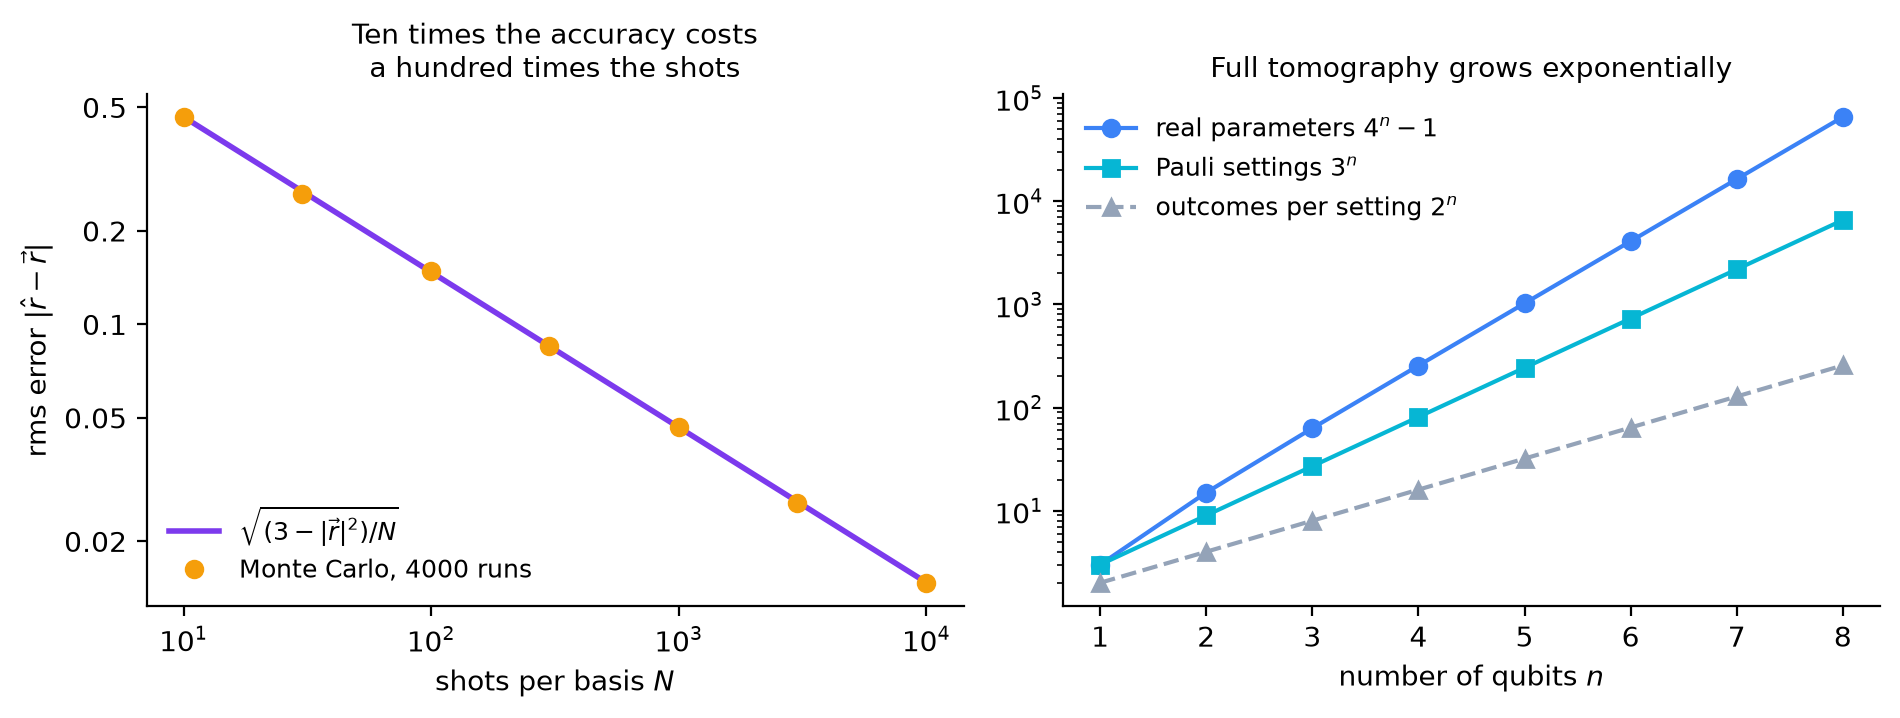

In [5]:
_show_mpl(_lessonfigs.tomography_costs())

*Left: the root mean squared error of linear inversion for $\vec r = (0.5, 0.3, 0.7)$ follows $\sqrt{(3 - |\vec r|^2)/N}$. Right: an $n$-qubit density matrix has $4^n - 1$ real parameters, and measuring every qubit in $X$, $Y$ or $Z$ needs $3^n$ settings.*

For $n$ qubits the same construction expands $\rho$ in the $4^n$ tensor products of $I, X, Y, Z$; one coefficient is fixed by the trace, leaving $4^n - 1$ real parameters. Measuring each qubit in one of $X$, $Y$, $Z$ gives $3^n$ settings, and each setting estimates many Pauli expectations at once from its $2^n$ outcomes. For 10 qubits that is 59049 settings and over a million parameters, before any shots are counted [@nielsenchuang; @preskill]. Assumptions such as low rank or a known family of states reduce the cost but also restrict what the result can claim; and a flexible estimator such as a neural network cannot recover parameters that the measurement design does not identify. If the goal is a list of selected properties rather than the full matrix, randomized-measurement methods such as classical shadows need far fewer samples [@shadows].

:::{caution} What the error bars do not cover
The variance in [](#eq-l5-09-mse) is shot noise only. It assumes a stable preparation, independent copies, and measurements that really are $X$, $Y$ and $Z$. Miscalibrated measurements or drifting preparations cause systematic errors that more shots do not reduce and that these error bars do not show.
:::

## Worked example

:::{admonition} From counts to a physical state
:class: tip

A qubit source is measured with $N = 200$ shots in each basis. The numbers of $+1$ outcomes are 186 for $X$, 100 for $Y$ and 160 for $Z$. Estimate the state, check that it is physical, correct it if necessary, and judge whether the data are consistent with a pure state.

1. Linear inversion: $\hat r_i = (2n_i^{+} - N)/N$ gives $\hat r_x = (372 - 200)/200 = 0.86$, $\hat r_y = 0$, $\hat r_z = (320 - 200)/200 = 0.6$.
2. Length: $|\hat{\vec r}| = \sqrt{0.86^2 + 0.6^2} = \sqrt{1.0996} \approx 1.0486 > 1$. The eigenvalues $(1 \pm 1.0486)/2$ are $1.0243$ and $-0.0243$, so $\hat\rho$ is not a density operator.
3. Projection by [](#prop-l5-09-project): $\hat{\vec r}/|\hat{\vec r}| \approx (0.820, 0, 0.572)$. The corrected state is pure, with eigenvalues 1 and 0 and entropy 0 bits.
4. Shot noise: by [](#prop-l5-09-noise) the standard errors are $\sqrt{(1 - 0.86^2)/200} \approx 0.036$ for $x$ and $\sqrt{(1 - 0.6^2)/200} \approx 0.057$ for $z$. Propagating them to the length gives about 0.044, so the excess $1.0486 - 1 = 0.049$ is about one standard error.

**Result.** The projected estimate is the pure state with Bloch vector $(0.820, 0, 0.572)$. Leaving the ball by about one standard error is ordinary shot noise for a nearly pure source, not evidence of a faulty device.
:::

## Exercises

**1. (Core)** A qubit has Bloch vector $\vec r = (0.3, 0.4, 0)$. Find its eigenvalues and its entropy in bits and in nats.

:::{dropdown} Solution
$|\vec r| = \sqrt{0.09 + 0.16} = 0.5$, so the eigenvalues are $0.75$ and $0.25$. $S = -0.75\log_2 0.75 - 0.25\log_2 0.25 \approx 0.311 + 0.5 = 0.811$ bits, which is $0.811\ln 2 \approx 0.562$ nats.
:::

**2. (Core)** A fitted Bloch vector is $(0, 0, 1)$. Give the eigenvalues and the entropy. Can more samples reveal a global phase of the state?

:::{dropdown} Solution
The eigenvalues are $(1 \pm 1)/2 = 1$ and $0$, so $S = 0$: the state $|0\rangle$ is pure. No: $|\psi\rangle$ and $e^{i\gamma}|\psi\rangle$ give the same $\rho = |\psi\rangle\langle\psi|$, hence the same outcome probabilities for every measurement, so no number of samples can reveal a global phase.
:::

**3. (Stretch)** How many shots per basis guarantee a standard error of at most 0.01 on every Bloch component, whatever the state? How many suffice if you already know $|r_i| \ge 0.9$ for one component?

:::{dropdown} Solution
$\operatorname{Var}\hat r_i = (1 - r_i^2)/N \le 1/N$, so $N \ge 1/0.01^2 = 10000$ guarantees it. If $|r_i| \ge 0.9$ the variance is at most $0.19/N$, so $N \ge 0.19/0.0001 = 1900$ suffices for that component.
:::

**4. (Stretch)** Show that $\operatorname{Tr}(\rho\sigma) = (1 + \vec r\cdot\vec s)/2$ for qubit states with Bloch vectors $\vec r$ and $\vec s$, and deduce $\|\rho - \sigma\|_2^2 = \tfrac12|\vec r - \vec s|^2$.

:::{dropdown} Solution
$\operatorname{Tr}(\rho\sigma) = \tfrac14\operatorname{Tr}\big((I + \vec r\cdot\vec\sigma)(I + \vec s\cdot\vec\sigma)\big) = \tfrac14\big(2 + 0 + 0 + \sum_{ij} r_i s_j\operatorname{Tr}(\sigma_i\sigma_j)\big) = \tfrac14(2 + 2\vec r\cdot\vec s)$. Then $\|\rho - \sigma\|_2^2 = \operatorname{Tr}\rho^2 + \operatorname{Tr}\sigma^2 - 2\operatorname{Tr}(\rho\sigma) = \tfrac{1 + |\vec r|^2}{2} + \tfrac{1 + |\vec s|^2}{2} - (1 + \vec r\cdot\vec s) = \tfrac12|\vec r - \vec s|^2$.
:::

**5. (Challenge)** Two qubits are measured in the 9 local settings $\sigma_a\otimes\sigma_b$ with $a, b \in \{x, y, z\}$, each setting giving a pair of signs $(s, t)$. Show that all 15 expectation values $\langle\sigma_a\otimes\sigma_b\rangle$ with $a, b \in \{0, x, y, z\}$ not both 0 (where $\sigma_0 = I$) can be computed from these data, and say how many settings supply each one.

:::{dropdown} Solution
In setting $(a, b)$, $\langle\sigma_a\otimes\sigma_b\rangle = \mathbb{E}[st]$, $\langle\sigma_a\otimes I\rangle = \mathbb{E}[s]$ and $\langle I\otimes\sigma_b\rangle = \mathbb{E}[t]$. Each of the 9 correlators comes from exactly one setting. Each of the 3 local terms $\langle\sigma_a\otimes I\rangle$ comes from the 3 settings $(a, x), (a, y), (a, z)$, and likewise each $\langle I\otimes\sigma_b\rangle$ from 3 settings. So $9 + 3 + 3 = 15 = 4^2 - 1$ parameters are covered by $3^2 = 9$ settings, and the local terms can be averaged over three settings each. The same argument shows that $3^n$ settings suffice for $n$ qubits.
:::

## Check your understanding

**1. What is the von Neumann entropy, in bits, of the qubit with Bloch vector $(0, 0, 0.6)$?**

- **A.** About 0.971
- **B.** 0.6
- **C.** About 0.722
- **D.** 0.4

:::{dropdown} Show the answer
**C. About 0.722**

The eigenvalues are $(1 \pm 0.6)/2 = 0.8$ and $0.2$, and $-0.8\log_2 0.8 - 0.2\log_2 0.2 \approx 0.722$ bits. The entropy depends on the Bloch length through $h\big((1 + |\vec r|)/2\big)$, not linearly on it.
:::

**2. Which data determine a qubit density operator?**

- **A.** Many repeated $Z$ outcomes
- **B.** Its purity and its $Z$ expectation value
- **C.** Its von Neumann entropy
- **D.** The expectation values of $X$, $Y$ and $Z$

:::{dropdown} Show the answer
**D. The expectation values of $X$, $Y$ and $Z$**

By the Pauli reconstruction theorem, $\rho = \tfrac12(I + r_x X + r_y Y + r_z Z)$ with $r_i = \langle\sigma_i\rangle$. One basis fixes only one component, and the entropy or the purity fixes only the length $|\vec r|$.
:::

**3. A linear-inversion estimate has $|\hat{\vec r}| = 1.05$. Which statement is correct?**

- **A.** The entropy of the estimate is negative
- **B.** The state is more than pure
- **C.** $\hat\rho$ has a negative eigenvalue, $-0.025$
- **D.** The measurement device must be broken

:::{dropdown} Show the answer
**C. $\hat\rho$ has a negative eigenvalue, $-0.025$**

The eigenvalues are $(1 \pm 1.05)/2 = 1.025$ and $-0.025$. That is shot noise around a nearly pure state; project to $\hat{\vec r}/|\hat{\vec r}|$ to get the closest valid state.
:::

**4. What is the purity $\operatorname{Tr}\rho^2$ of $\rho = \operatorname{diag}(0.8, 0.2)$?** *(Review of [L5-05](#lesson-l5-05))*

- **A.** 0.5
- **B.** 0.68
- **C.** 1
- **D.** 0.6

:::{dropdown} Show the answer
**B. 0.68**

$0.8^2 + 0.2^2 = 0.64 + 0.04 = 0.68$. For a qubit, purity $(1 + |\vec r|^2)/2$ and entropy $h\big((1 + |\vec r|)/2\big)$ are both functions of $|\vec r| = 0.6$; this state has entropy 0.722 bits.
:::

## Common misconceptions

- **The entropy of a state equals the entropy of its measurement outcomes.** Only in an eigenbasis. In any other basis the outcome entropy is larger: $|{+}\rangle$ has $S = 0$ but fair-coin $Z$ outcomes with 1 bit of entropy.
- **An estimate outside the Bloch ball means the experiment failed.** Linear inversion of finite counts often leaves the ball for nearly pure states; with $N$ shots per basis the excess is typically of order $1/\sqrt N$. Project onto the ball and report the shot-noise error.
- **Enough shots in a single basis will eventually reveal the state.** Shots in the $Z$ basis estimate only $r_z$. The states $|{+}\rangle$, $|{-}\rangle$ and $I/2$ all give $r_z = 0$; at least three linearly independent settings are needed.
- **A clever estimator, for example a neural network, can avoid the exponential cost of tomography without assumptions.** An estimator cannot recover parameters that the measurement design leaves unidentified. Savings come from assumptions about the state or from asking for fewer properties, and those choices limit the conclusion.

:::{caution} Scope and limits
Logarithms are base 2 throughout, so entropies are in bits. $N$ is the number of shots in each of the three bases. The error formula [](#eq-l5-09-mse) assumes independent, identically prepared copies and ideal Pauli measurements; preparation and measurement errors are not included, and tomography's conclusions are only as good as the calibration of the measurement model. Radial projection is one of several valid ways to restore physicality, and the error bars of a projected estimate are no longer the simple formula. The simulations here are classical computations, not experiments.
:::

:::{seealso} Where this leads
[L5-10](#lesson-l5-10) watches Bloch vectors shrink under noise and asks how encoding protects them. Process tomography, which characterizes a channel rather than a state, applies the same reconstruction to a channel's Choi matrix in Level 6. Classical shadows in Level 7 replace full tomography by randomized measurements that predict many properties from few samples [@shadows].
:::

:::{dropdown} For instructors

**Why this lesson.** Students often equate the state with the statistics of one measurement. Separating the entropy of the state from the entropy of outcomes, and then showing that three bases suffice and one does not, makes the operational meaning of a density operator concrete [@nielsenchuang; @preskill]. The physicality problem is a natural first encounter with constrained estimation [@watrous].

**Teaching notes.**

- Begin with the $|0\rangle$, $|{+}\rangle$, $I/2$ puzzle and let students propose measurements before showing [](#thm-l5-09-recon).
- Ask students to predict the share of estimates outside the ball for a nearly pure state at small $N$ before moving the slider; many expect it to be rare.
- Connect [](#prop-l5-09-measure) to the concavity arguments of [L3-08](#lesson-l3-08); Jensen's inequality is the only tool needed [@coverthomas].

**Assessment.** The worked example and the stretch exercise on shot counts test the full pipeline from counts to a defended estimate; the challenge exercise checks that students can generalize the counting to two qubits.

**Going further.** Derive the maximum-likelihood estimate for one qubit numerically and compare it with radial projection on simulated data, or read how classical shadows predict many observables from few measurements [@shadows]. Nielsen and Chuang, Section 8.4, treats state and process tomography [@nielsenchuang].

:::

## References

This lesson draws on [@nielsenchuang; @watrous; @preskill; @coverthomas; @shadows].

**Further reading.**

- [@coverthomas]: Chapter 2 develops Shannon entropy, relative entropy and Jensen's inequality used in the proofs here.
- [@watrous]: Chapter 5 treats von Neumann entropy with full proofs.
- [@shadows]: How randomized measurements predict many properties without full tomography.

**Next:** [L5-10 · Noise, encoding, and error correction](#lesson-l5-10)
